<center><h1>Zambrano_Claudia_HW4</h1></center>
<br>
<br>

Name: Claudia Zambrano
<br>
Github Username: claudia-z712
<br>
USC ID: 8224948861

## 1. Time Series Classification Part 1: Feature Creation/Extraction (HW3 Rerun)

### (a) Obtain Data

Import packages

In [1]:
import os
import zipfile
import shutil
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

Get the AReM Data Set

In [2]:
zip_filepath = r"C:\Users\Claudia\OneDrive\Desktop\HW_4\activity+recognition+system+based+on+multisensor+data+fusion+arem (1).zip"
extract_path = "AReM_data"

# Remove the existing extraction folder to avoid leftover files
if os.path.exists(extract_path):
    shutil.rmtree(extract_path)

os.makedirs(extract_path)

# Extract everything, skipping only the extra top-level folder
with zipfile.ZipFile(zip_filepath, 'r') as zip_ref:
    for file in zip_ref.namelist():
        parts = file.split('/', 1)

        # Skip the top-level directory itself
        if len(parts) > 1 and parts[1]:
            relative_path = parts[1]
            destination = os.path.join(extract_path, relative_path)

            if file.endswith('/'):
                os.makedirs(destination, exist_ok=True)
            else:
                os.makedirs(os.path.dirname(destination), exist_ok=True)
                with zip_ref.open(file) as source, open(destination, 'wb') as target:
                    shutil.copyfileobj(source, target)

# List contents of the extracted folder
if os.path.exists(extract_path):
    print("Contents:", os.listdir(extract_path))

Contents: ['bending1', 'bending2', 'bendingType.pdf', 'cycling', 'lying', 'sensorsPlacement.pdf', 'sitting', 'standing', 'walking']


### (b) Splitting Data

In [3]:
# Source and target directories
src_dir = "C:/Users/Claudia/OneDrive/Desktop/HW_4/AReM_data"
# Note: Sometimes extracted contents are nested in a subdirectory (like 'AReM' or similar)
# Let's locate the actual root folder containing the class directories
subfolders = [f for f in os.listdir(src_dir) if os.path.isdir(os.path.join(src_dir, f))]
actual_src = os.path.join(src_dir, subfolders[0]) if len(subfolders) == 1 and subfolders[0].lower() in ['arem', 'data'] else src_dir

test_dir = "Testing-Data"
train_dir = "Training-Data"

os.makedirs(test_dir, exist_ok=True)
os.makedirs(train_dir, exist_ok=True)

# Iterate through each folder (category) inside the source dataset
for category in os.listdir(actual_src):
    category_path = os.path.join(actual_src, category)
    if not os.path.isdir(category_path) or category.startswith('.'):
        continue

    # Create category subdirectories inside Testing and Training folders
    os.makedirs(os.path.join(test_dir, category), exist_ok=True)
    os.makedirs(os.path.join(train_dir, category), exist_ok=True)

    # Get and sort all dataset files (assuming format like dataset1.csv, dataset2.csv, etc.)
    files = sorted([f for f in os.listdir(category_path) if f.endswith('.csv')])

    for f in files:
        src_file_path = os.path.join(category_path, f)

        # Determine if the file is a test or train instance
        is_test = False

        if category in ['bending1', 'bending2']:
            # Place dataset1 and dataset2 into testing
            if f in ['dataset1.csv', 'dataset2.csv']:
                is_test = True
        else:
            # Place dataset1, dataset2, and dataset3 into testing
            if f in ['dataset1.csv', 'dataset2.csv', 'dataset3.csv']:
                is_test = True

        # Copy to the corresponding target directory
        if is_test:
            shutil.copy(src_file_path, os.path.join(test_dir, category, f))
        else:
            shutil.copy(src_file_path, os.path.join(train_dir, category, f))

print("Splitting complete!")
print(f"Testing-Data classes: {os.listdir(test_dir)}")
print(f"Training-Data classes: {os.listdir(train_dir)}")

Splitting complete!
Testing-Data classes: ['bending1', 'bending2', 'cycling', 'lying', 'sitting', 'standing', 'walking']
Training-Data classes: ['bending1', 'bending2', 'cycling', 'lying', 'sitting', 'standing', 'walking']


### (c) Feature Extraction

In [4]:
src_dir = "C:/Users/Claudia/OneDrive/Desktop/HW_4/AReM_data"
# Get all subdirectories (categories) in alphabetical order
categories = sorted([d for d in os.listdir(src_dir) if os.path.isdir(os.path.join(src_dir, d))])

all_instances_features = []

for category in categories:
    category_path = os.path.join(src_dir, category)
    files = sorted(
        [f for f in os.listdir(category_path) if f.endswith('.csv')],
        key=lambda x: int(''.join(filter(str.isdigit, x)) or 0)
    )

    for f in files:
        file_path = os.path.join(category_path, f)

        # Standardized reading mechanism:
        # Skip first 4 rows (0-indexed 0,1,2,3), so Row 5 (index 4) becomes the header
        try:
            df = pd.read_csv(file_path, skiprows=4)
        except Exception:
            df = pd.read_csv(file_path, skiprows=4, sep=r'\s+')

        # Convert everything to numeric values
        df = df.apply(pd.to_numeric, errors='coerce')
        df = df.dropna(subset=[df.columns[0]]) # Drop rows where time is NaN

        # The first column is 'time', the next 6 are the sensor time series
        time_col = df.columns[0]
        ts_cols = df.columns[1:7]

        ts_data = df[ts_cols]

        instance_info = {
            'Category': category,
            'Instance': f.replace('.csv', '')
        }

        # Extract features for each of the 6 columns
        for col_idx, col_name in enumerate(ts_cols):
            col_data = ts_data[col_name]

            # Calculate time-domain statistics and round to 3 decimal places
            instance_info[f'col{col_idx+1}_min'] = round(float(col_data.min()), 3)
            instance_info[f'col{col_idx+1}_max'] = round(float(col_data.max()), 3)
            instance_info[f'col{col_idx+1}_mean'] = round(float(col_data.mean()), 3)
            instance_info[f'col{col_idx+1}_median'] = round(float(col_data.median()), 3)
            instance_info[f'col{col_idx+1}_std'] = round(float(col_data.std()), 3)
            instance_info[f'col{col_idx+1}_1st_quart'] = round(float(col_data.quantile(0.25)), 3)
            instance_info[f'col{col_idx+1}_3rd_quart'] = round(float(col_data.quantile(0.75)), 3)

        all_instances_features.append(instance_info)

# Create final structured table
features_df = pd.DataFrame(all_instances_features)
print(f"Extracted features for {features_df.shape[0]} instances across all categories.")
pd.set_option('display.max_columns', None)
display(features_df)


Extracted features for 88 instances across all categories.


,Category,Instance,col1_min,col1_max,col1_mean,col1_median,col1_std,col1_1st_quart,col1_3rd_quart,col2_min,col2_max,col2_mean,col2_median,col2_std,col2_1st_quart,col2_3rd_quart,col3_min,col3_max,col3_mean,col3_median,col3_std,col3_1st_quart,col3_3rd_quart,col4_min,col4_max,col4_mean,col4_median,col4_std,col4_1st_quart,col4_3rd_quart,col5_min,col5_max,col5_mean,col5_median,col5_std,col5_1st_quart,col5_3rd_quart,col6_min,col6_max,col6_mean,col6_median,col6_std,col6_1st_quart,col6_3rd_quart
0,bending1,dataset1,37.25,45.00,40.625,40.50,1.477,39.25,42.000,0.0,1.30,0.359,0.430,0.323,0.00,0.500,4.00,29.50,19.041,19.250,4.463,16.00,23.250,0.0,7.23,0.833,0.50,0.966,0.000,1.120,27.25,38.25,34.311,35.00,2.188,33.000,36.00,0.00,1.92,0.571,0.43,0.583,0.000,1.300
1,bending1,dataset2,38.00,45.67,42.813,42.50,1.436,42.00,43.670,0.0,1.22,0.372,0.470,0.289,0.00,0.500,2.00,29.50,20.097,21.000,3.894,19.00,22.250,0.0,5.76,0.876,0.50,1.047,0.000,1.145,27.67,38.50,33.025,33.00,1.995,32.000,34.50,0.00,3.11,0.571,0.43,0.601,0.000,1.300
2,bending1,dataset3,35.00,47.40,43.955,44.33,1.559,43.00,45.000,0.0,1.70,0.426,0.470,0.339,0.00,0.500,6.50,29.75,22.122,23.000,3.031,19.75,24.000,0.0,4.44,0.497,0.43,0.551,0.000,0.830,29.00,38.50,35.588,36.00,2.000,35.362,36.50,0.00,1.79,0.493,0.43,0.514,0.000,0.940
3,bending1,dataset4,33.00,47.75,42.180,43.50,3.671,39.15,45.000,0.0,3.00,0.696,0.500,0.631,0.00,1.120,8.50,30.00,22.184,23.000,3.810,20.50,24.372,0.0,5.15,0.990,0.83,0.954,0.430,1.300,20.00,38.67,33.494,35.00,3.849,30.457,36.33,0.00,2.18,0.614,0.50,0.524,0.000,1.000
4,bending1,dataset5,33.00,45.75,41.678,41.75,2.243,41.33,42.750,0.0,2.83,0.536,0.500,0.405,0.43,0.710,3.00,28.25,19.007,19.125,4.087,16.50,22.062,0.0,6.42,0.842,0.50,0.929,0.430,1.120,23.67,37.50,29.857,30.00,2.411,28.457,31.25,0.00,1.79,0.383,0.43,0.389,0.000,0.500
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
83,walking,dataset11,19.50,45.33,33.587,34.25,4.651,30.25,37.000,0.0,14.67,4.577,4.260,2.461,2.87,6.105,7.33,23.25,15.318,15.330,2.970,13.25,17.270,0.0,9.00,3.227,3.10,1.647,2.050,4.260,6.33,25.00,15.892,16.00,3.284,13.730,18.25,0.00,8.32,3.260,3.11,1.640,2.050,4.322
84,walking,dataset12,19.75,45.50,34.323,35.25,4.752,31.00,38.000,0.0,13.47,4.456,3.900,2.599,2.49,5.970,6.25,22.25,15.210,15.250,2.711,13.50,17.000,0.0,9.00,3.277,3.11,1.500,2.170,4.390,6.25,23.25,15.550,15.75,3.120,13.500,17.75,0.00,9.67,3.433,3.20,1.733,2.157,4.565
85,walking,dataset13,19.50,46.00,34.546,35.25,4.842,31.25,37.812,0.0,12.47,4.372,4.135,2.360,2.49,5.800,7.00,22.67,15.186,15.250,2.758,13.25,17.000,0.0,8.34,3.029,2.86,1.665,1.790,4.110,7.00,22.75,15.760,15.75,2.823,14.000,17.75,0.00,10.00,3.338,3.08,1.657,2.160,4.335
86,walking,dataset14,23.50,46.25,34.873,35.25,4.532,31.75,38.250,0.0,14.82,4.381,3.925,2.435,2.50,5.933,6.67,24.25,15.471,15.500,2.813,13.50,17.250,0.0,9.90,3.206,3.03,1.519,2.058,4.190,5.50,23.50,15.874,16.00,3.131,13.750,18.00,0.00,9.51,3.425,3.27,1.691,2.170,4.500


## 2. Time Series Classification Part 2: Binary and Multiclass Classification

### (a) Binary Classification Using Logistic Regression

#### i. Plots

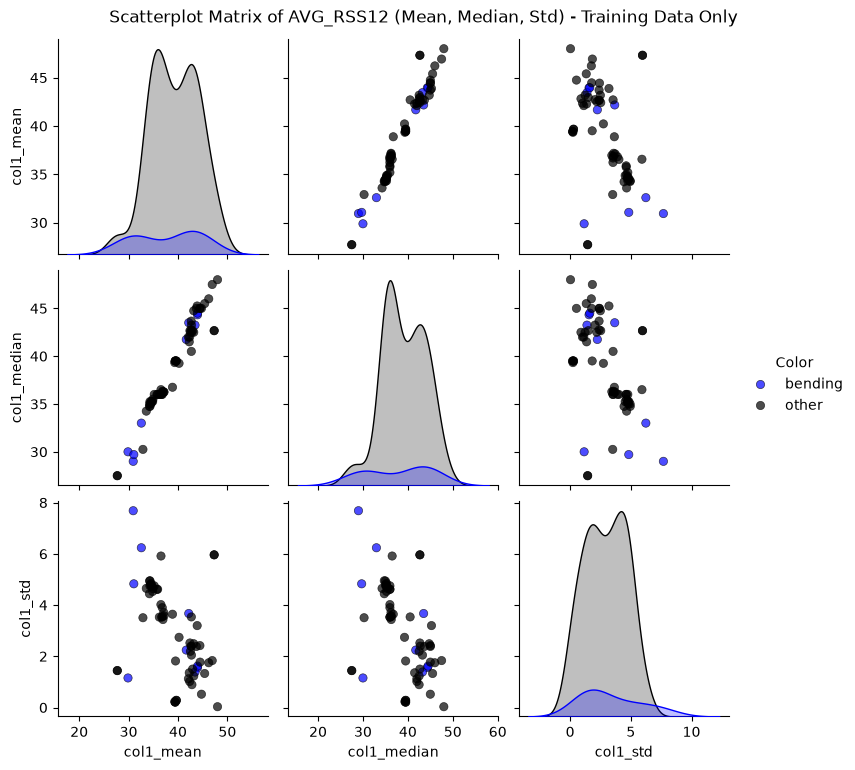

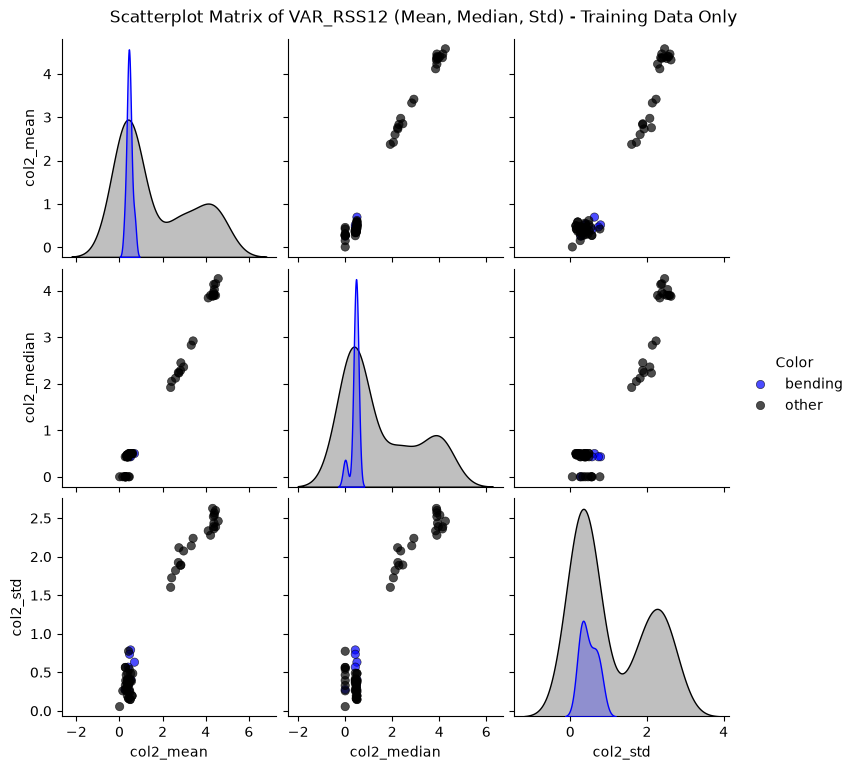

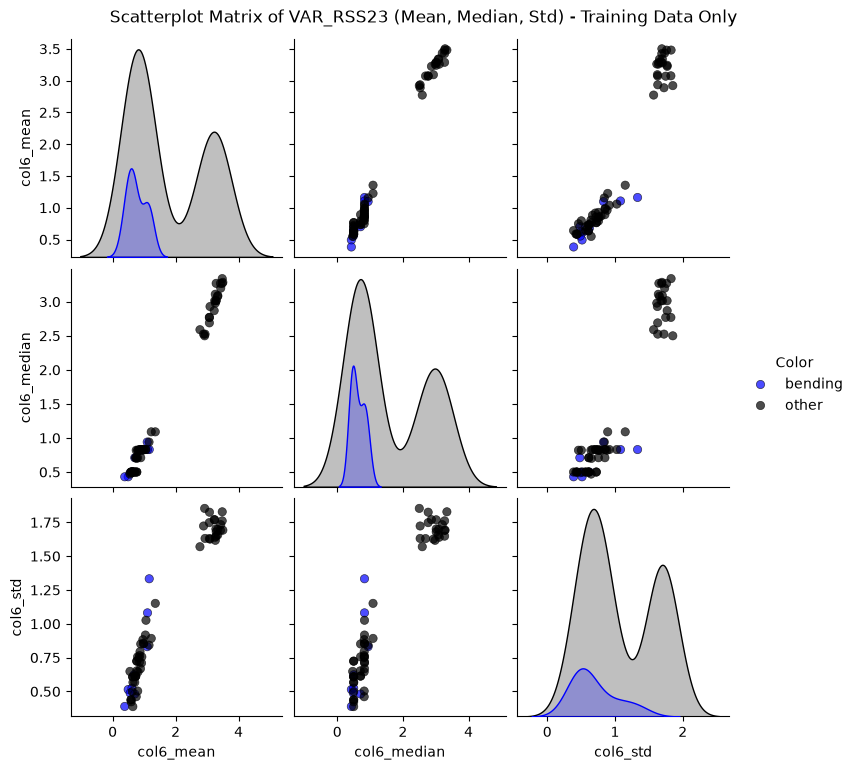

In [5]:
# Define the training directory
train_dir = "Training-Data"

# Filter features_df to only include instances present in the Training-Data folder
training_instances = []
for idx, row in features_df.iterrows():
    category = row['Category']
    instance = row['Instance']
    expected_path = os.path.join(train_dir, category, f"{instance}.csv")
    if os.path.exists(expected_path):
        training_instances.append(row)

train_features_df = pd.DataFrame(training_instances).reset_index(drop=True)

# Define color mapping: blue for bending1 and bending2, black for others
train_features_df['Color'] = train_features_df['Category'].apply(
    lambda cat: 'bending' if cat in ['bending1', 'bending2'] else 'other'
)

# Features needed for the scatterplot matrix
plot_cols = ['col1_mean', 'col1_median', 'col1_std']

# Create the scatterplot matrix (pairplot)
g = sns.pairplot(
    train_features_df,
    vars=plot_cols,
    hue='Color',
    palette={'bending': 'blue', 'other': 'black'},
    plot_kws={'alpha': 0.7, 'edgecolor': 'k'}
)

# Adjust title and display
g.fig.suptitle("Scatterplot Matrix of AVG_RSS12 (Mean, Median, Std) - Training Data Only", y=1.02)
plt.show()



# Features needed for Column 2 scatterplot matrix
plot_cols_col2 = ['col2_mean', 'col2_median', 'col2_std']

# Create the scatterplot matrix (pairplot) for Column 2
g_col2 = sns.pairplot(
    train_features_df,
    vars=plot_cols_col2,
    hue='Color',
    palette={'bending': 'blue', 'other': 'black'},
    plot_kws={'alpha': 0.7, 'edgecolor': 'k'}
)

# Adjust title and display
g_col2.fig.suptitle("Scatterplot Matrix of VAR_RSS12 (Mean, Median, Std) - Training Data Only", y=1.02)
plt.show()


#Features needed for Column 6 scatterplot matrix
plot_cols_col6 = ['col6_mean', 'col6_median', 'col6_std']

# Create the scatterplot matrix (pairplot) for Column 6
g_col6 = sns.pairplot(
    train_features_df,
    vars=plot_cols_col6,
    hue='Color',
    palette={'bending': 'blue', 'other': 'black'},
    plot_kws={'alpha': 0.7, 'edgecolor': 'k'}
)

# Adjust title and display
g_col6.fig.suptitle("Scatterplot Matrix of VAR_RSS23 (Mean, Median, Std) - Training Data Only", y=1.02)
plt.show()

#### ii. Splitted Plots

In [6]:
#Visually show the new data we are working with. 
#Seperated data into 2 sections each named A or B.

train_dir = "Training-Data"
categories = sorted([d for d in os.listdir(train_dir) if os.path.isdir(os.path.join(train_dir, d))])

split_features = []

for category in categories:
    category_path = os.path.join(train_dir, category)
    files = sorted(
        [f for f in os.listdir(category_path) if f.endswith('.csv')],
        key=lambda x: int(''.join(filter(str.isdigit, x)) or 0)
    )

    for f in files:
        file_path = os.path.join(category_path, f)

        try:
            df_temp = pd.read_csv(file_path, skiprows=4)
        except Exception:
            df_temp = pd.read_csv(file_path, skiprows=4, sep=r'\s+')

        # Clean up column names to avoid whitespace or comment issues
        df_temp.columns = [c.strip().replace('# ', '').replace('Columns: ', '') for c in df_temp.columns]
        
        df_temp = df_temp.apply(pd.to_numeric, errors='coerce')
        df_temp = df_temp.dropna()
        
        if len(df_temp) < 2:
            continue

        # Safely find corresponding columns by checking standard names or falling back to index
        def get_col_data(df, target_idx, substring):
            for col in df.columns:
                if substring in col.lower():
                    return df[col]
            return df[df.columns[target_idx]]

        try:
            col1_data = get_col_data(df_temp, 1, 'avg_rss12')
            col2_data = get_col_data(df_temp, 2, 'var_rss12')
            col6_data = get_col_data(df_temp, 6, 'var_rss23')
        except Exception:
            # Skip if file structure is completely unexpected
            continue

        n = len(df_temp)
        half = n // 2

        col1_A = col1_data.iloc[:half]
        col1_B = col1_data.iloc[half:]

        col2_A = col2_data.iloc[:half]
        col2_B = col2_data.iloc[half:]

        col6_A = col6_data.iloc[:half]
        col6_B = col6_data.iloc[half:]

        split_features.append({
            'Category': category,
            'Instance': f.replace('.csv', ''),
            'col1_A_mean': round(float(col1_A.mean()), 3),
            'col1_A_median': round(float(col1_A.median()), 3),
            'col1_A_std': round(float(col1_A.std()), 3) if len(col1_A) > 1 else 0.0,
            'col1_B_mean': round(float(col1_B.mean()), 3),
            'col1_B_median': round(float(col1_B.median()), 3),
            'col1_B_std': round(float(col1_B.std()), 3) if len(col1_B) > 1 else 0.0,
            'col2_A_mean': round(float(col2_A.mean()), 3),
            'col2_A_median': round(float(col2_A.median()), 3),
            'col2_A_std': round(float(col2_A.std()), 3) if len(col2_A) > 1 else 0.0,
            'col2_B_mean': round(float(col2_B.mean()), 3),
            'col2_B_median': round(float(col2_B.median()), 3),
            'col2_B_std': round(float(col2_B.std()), 3) if len(col2_B) > 1 else 0.0,
            'col6_A_mean': round(float(col6_A.mean()), 3),
            'col6_A_median': round(float(col6_A.median()), 3),
            'col6_A_std': round(float(col6_A.std()), 3) if len(col6_A) > 1 else 0.0,
            'col6_B_mean': round(float(col6_B.mean()), 3),
            'col6_B_median': round(float(col6_B.median()), 3),
            'col6_B_std': round(float(col6_B.std()), 3) if len(col6_B) > 1 else 0.0
        })

split_features_df = pd.DataFrame(split_features)
display(split_features_df)

,Category,Instance,col1_A_mean,col1_A_median,col1_A_std,col1_B_mean,col1_B_median,col1_B_std,col2_A_mean,col2_A_median,col2_A_std,col2_B_mean,col2_B_median,col2_B_std,col6_A_mean,col6_A_median,col6_A_std,col6_B_mean,col6_B_median,col6_B_std
0,bending1,dataset3,44.057,44.500,1.557,43.852,43.500,1.557,0.381,0.470,0.330,0.471,0.500,0.342,0.598,0.500,0.527,0.388,0.000,0.479
1,bending1,dataset4,43.279,45.000,3.473,41.081,42.000,3.537,0.673,0.485,0.634,0.719,0.500,0.628,0.641,0.765,0.555,0.586,0.470,0.492
2,bending1,dataset5,41.621,42.330,3.119,41.735,41.500,0.596,0.623,0.500,0.490,0.449,0.500,0.273,0.419,0.430,0.411,0.348,0.430,0.363
3,bending1,dataset6,44.117,45.000,1.360,42.793,42.670,1.059,0.250,0.000,0.314,0.506,0.500,0.261,0.815,0.710,0.718,0.544,0.500,0.473
4,bending1,dataset7,43.486,43.710,1.282,44.452,44.500,1.771,0.379,0.470,0.284,0.448,0.500,0.235,0.525,0.470,0.487,0.586,0.500,0.488
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
62,walking,dataset11,33.334,34.000,4.874,33.839,34.500,4.412,4.408,4.195,2.196,4.745,4.320,2.694,3.229,3.110,1.637,3.290,3.155,1.646
63,walking,dataset12,34.037,34.415,4.873,34.609,35.500,4.621,4.778,4.030,2.763,4.134,3.740,2.387,3.544,3.255,1.703,3.321,3.155,1.758
64,walking,dataset13,34.034,35.000,4.759,35.059,35.875,4.881,4.575,4.470,2.392,4.169,3.880,2.316,3.244,2.980,1.620,3.432,3.255,1.691
65,walking,dataset14,34.921,35.330,4.272,34.826,35.250,4.786,4.178,3.865,2.342,4.583,4.070,2.514,3.431,3.270,1.782,3.419,3.350,1.599


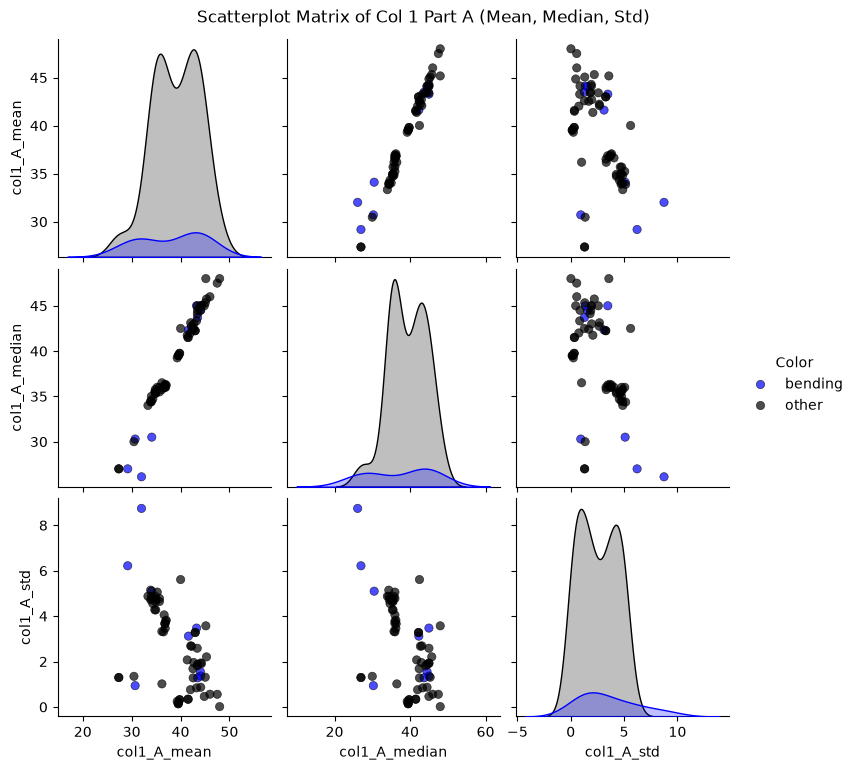

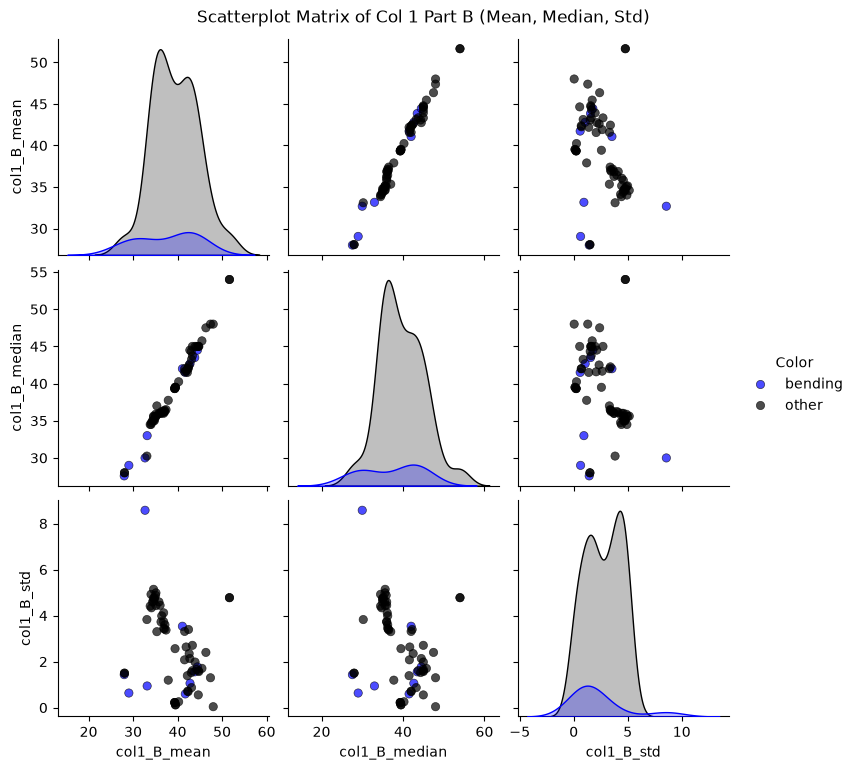

In [7]:
#Scatterplot Matrix for Time Series 1A and 1B

# Map colors for the split dataframe
split_features_df['Color'] = split_features_df['Category'].apply(
    lambda cat: 'bending' if cat in ['bending1', 'bending2'] else 'other'
)

# Select Column 1A features
cols_A = ['col1_A_mean', 'col1_A_median', 'col1_A_std']

# Create pairplot for Column 1A
g_A = sns.pairplot(
    split_features_df,
    vars=cols_A,
    hue='Color',
    palette={'bending': 'blue', 'other': 'black'},
    plot_kws={'alpha': 0.7, 'edgecolor': 'k'}
)
g_A.fig.suptitle("Scatterplot Matrix of Col 1 Part A (Mean, Median, Std)", y=1.02)
plt.show()

# Select Column 1B features
cols_B = ['col1_B_mean', 'col1_B_median', 'col1_B_std']

# Create pairplot for Column 1B
g_B = sns.pairplot(
    split_features_df,
    vars=cols_B,
    hue='Color',
    palette={'bending': 'blue', 'other': 'black'},
    plot_kws={'alpha': 0.7, 'edgecolor': 'k'}
)
g_B.fig.suptitle("Scatterplot Matrix of Col 1 Part B (Mean, Median, Std)", y=1.02)
plt.show()

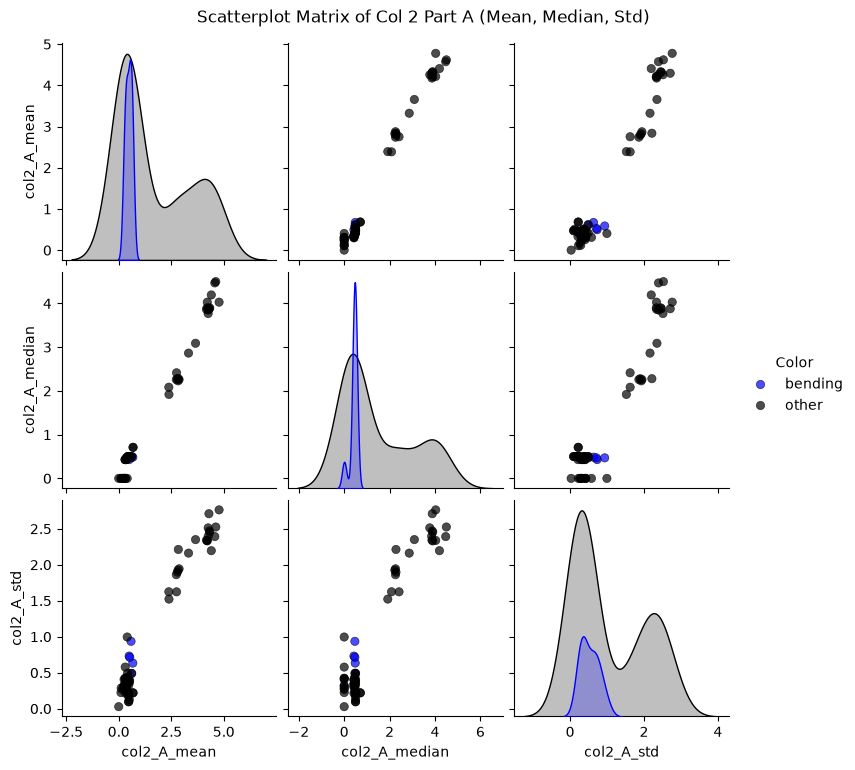

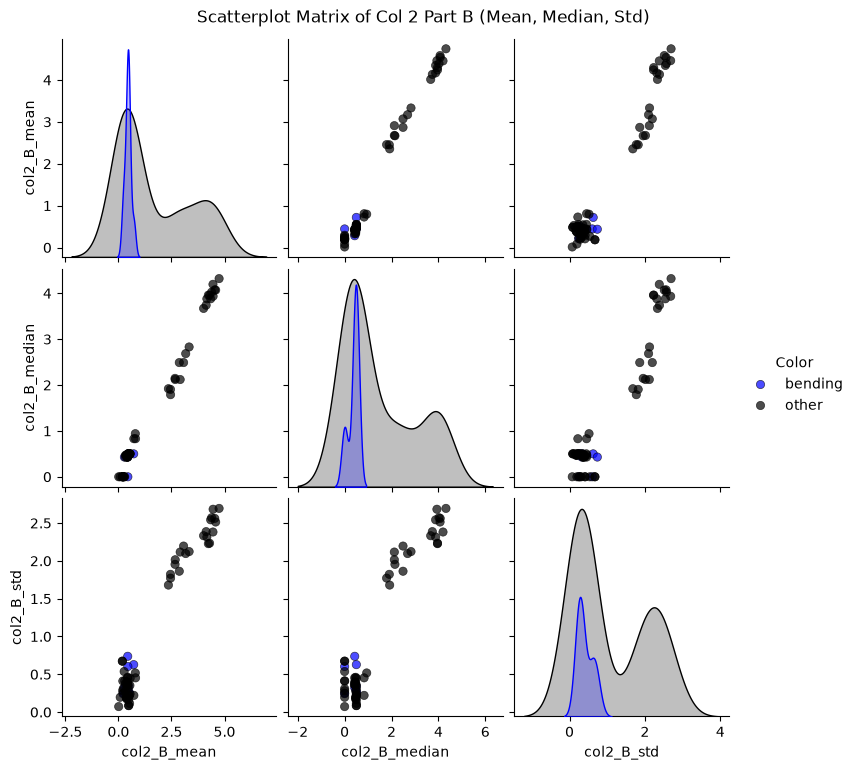

In [8]:
#Scatterplot Matrix for Time Series 2A and 2B

# Map colors for the split dataframe to ensure the 'Color' column is always present
split_features_df['Color'] = split_features_df['Category'].apply(
    lambda cat: 'bending' if cat in ['bending1', 'bending2'] else 'other'
)

# Select Column 2A features
cols_2A = ['col2_A_mean', 'col2_A_median', 'col2_A_std']

# Create pairplot for Column 2A
g_2A = sns.pairplot(
    split_features_df,
    vars=cols_2A,
    hue='Color',
    palette={'bending': 'blue', 'other': 'black'},
    plot_kws={'alpha': 0.7, 'edgecolor': 'k'}
)
g_2A.fig.suptitle("Scatterplot Matrix of Col 2 Part A (Mean, Median, Std)", y=1.02)
plt.show()

# Select Column 2B features
cols_2B = ['col2_B_mean', 'col2_B_median', 'col2_B_std']

# Create pairplot for Column 2B
g_2B = sns.pairplot(
    split_features_df,
    vars=cols_2B,
    hue='Color',
    palette={'bending': 'blue', 'other': 'black'},
    plot_kws={'alpha': 0.7, 'edgecolor': 'k'}
)
g_2B.fig.suptitle("Scatterplot Matrix of Col 2 Part B (Mean, Median, Std)", y=1.02)
plt.show()

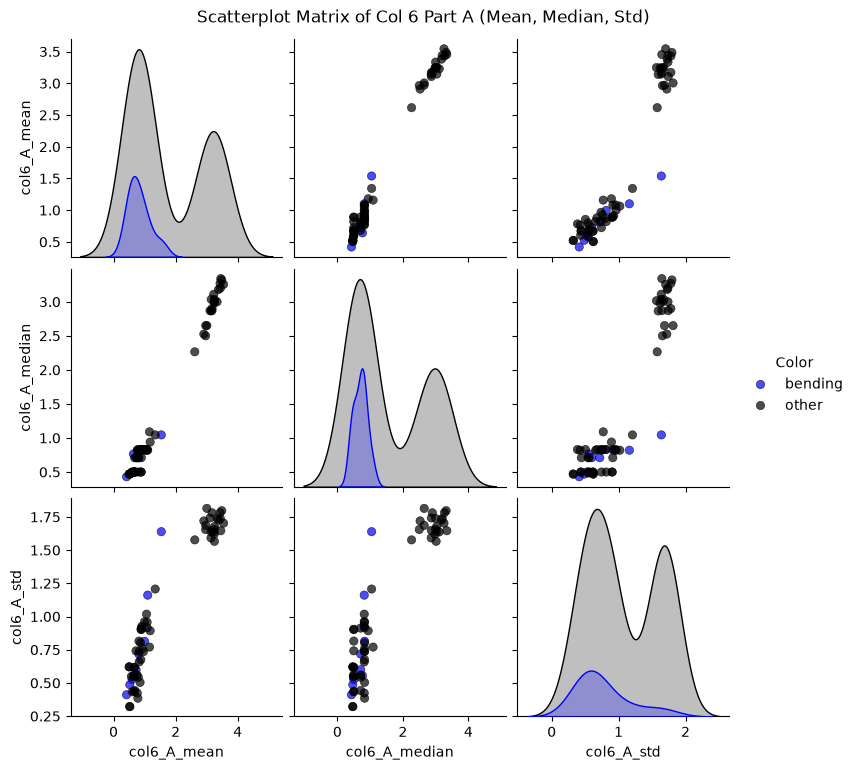

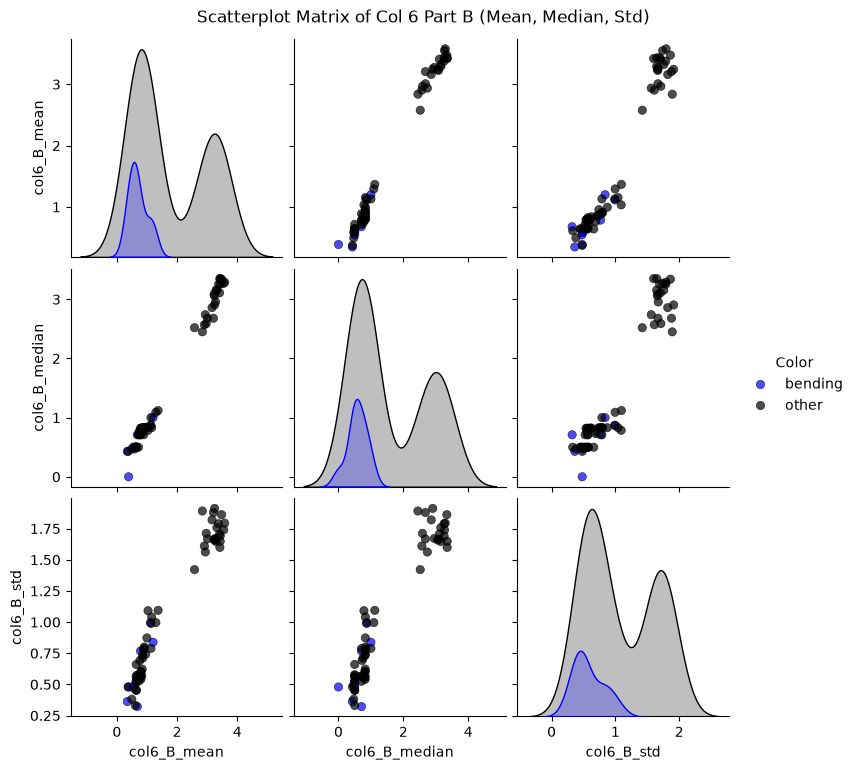

In [10]:
#Scatterplot Matrix for Time Series 6A and 6B
# Map colors for the split dataframe to ensure the 'Color' column is always present
split_features_df['Color'] = split_features_df['Category'].apply(
    lambda cat: 'bending' if cat in ['bending1', 'bending2'] else 'other'
)

# Select Column 6A features
cols_6A = ['col6_A_mean', 'col6_A_median', 'col6_A_std']

# Create pairplot for Column 6A
g_6A = sns.pairplot(
    split_features_df,
    vars=cols_6A,
    hue='Color',
    palette={'bending': 'blue', 'other': 'black'},
    plot_kws={'alpha': 0.7, 'edgecolor': 'k'}
)
g_6A.fig.suptitle("Scatterplot Matrix of Col 6 Part A (Mean, Median, Std)", y=1.02)
plt.show()

# Select Column 6B features
cols_6B = ['col6_B_mean', 'col6_B_median', 'col6_B_std']

# Create pairplot for Column 6B
g_6B = sns.pairplot(
    split_features_df,
    vars=cols_6B,
    hue='Color',
    palette={'bending': 'blue', 'other': 'black'},
    plot_kws={'alpha': 0.7, 'edgecolor': 'k'}
)
g_6B.fig.suptitle("Scatterplot Matrix of Col 6 Part B (Mean, Median, Std)", y=1.02)
plt.show()

#### iii. Time Series Segments

#### iv. Confusion Matrix

#### v. Test Classifier

#### vi. Separation

#### vii. Imbalance

### (b) Binary Classification Using L1-penalized logistic regression

#### i. Time Series Segments

#### ii. Comparison

### (c) Multi-class Classification (The Realistic Case)

#### i. Time Series Segments

#### ii. Naive Bayes

#### ii. Comparison

## 3. ISLR 4.8.3

## 4. ISLR 4.8.7

Assume a normal distribution with constant variance across the classes. Given:

\begin{array}{rcl}
\overline{X}_{Yes} & = & 10 \\
\overline{X}_{No} & = & 0 \\
\sigma^{2}_{Yes} = \sigma^{2}_{No} & = & 36 \\
\pi_{Yes} & = & 0.8 \\
\pi_{No} & = & 0.2 \\
\end{array}

Using Bayes' theorem assuming normal distribution

$$
p_k(x) =
\frac{
\pi_k \frac{1}{\sqrt{2\pi\sigma^2}}
\exp\left(-\frac{1}{2\sigma^2}(x-\mu_k)^2\right)
}{
\displaystyle\sum_{l=1}^{K}
\pi_l \frac{1}{\sqrt{2\pi\sigma^2}}
\exp\left(-\frac{1}{2\sigma^2}(x-\mu_l)^2\right)
}
$$

In [15]:
def f(x, mean, variance, prior):
    return prior * (1/np.sqrt(2 * np.pi * variance)) * np.exp((-1/(2*variance)) * (x - mean)**2)
f(4, 10, 36, 0.8)/(f(4, 0, 36, 0.2) + f(4, 10, 36, 0.8))


np.float64(0.7518524532975261)

\begin{array}{rcl}
p_{yes}(4) = 0.752
\end{array}

There is a 75% chance that a company will issue a dividen this year given that  profit was X=4